# Auxiliary-field annealing for a VMC guiding wave function

**Design draft — 2026-11-04. No auxiliary-field training results exist yet.**

Question: can temporary steering toward reproducible classical low-energy
configurations produce a better guide for the original quantum Hamiltonian,
after the steering field has been removed?

Agreed choices: existing periodic L6 samples and a classical candidate bank.
All numerical budgets, reference-selection rules and schedules below are
**proposed defaults**, ready for discussion. Executing this notebook checks
and displays the design; it does not run classical search, VMC or GFMC.

## Fixed physical problem

\[
H_0=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j
-0.15\sum_i Z_i-0.6\sum_i X_i,
\qquad N=3(6)^2=108,\quad K_{ij}\sim U(0.5,1.5).
\]

Use disorder IDs 60000 and 60001, training seeds 0 and 1, regular kagome
connectivity, periodic in both cell directions. Stored couplings use `J=-K`.
The existing disorder stream is
`default_rng(SeedSequence([20261027, 6, sample_id, 1]))`.
Save the actual points, ordered bonds and couplings and their hashes; IDs alone
are insufficient provenance. This is bond disorder on regular kagome.

An eventual amorphous OBC study requires its own graph definition and matched
Hamiltonians across solvers. Changing the current generator's boundary flag
also changes its coupling stream. This pilot makes no OBC/PBC scaling claim.

## Auxiliary term and what it guarantees

For a fixed candidate reference $s^\star_i\in\{-1,+1\}$, use
\[
D_\star=\frac12\sum_i(1-s_i^\star Z_i),\qquad
H_\epsilon=H_0+\epsilon D_\star.
\]
Here **$\epsilon$ is energy per mismatched spin**, so the added longitudinal
field coefficient is $\epsilon/2$ and the constant is $\epsilon N/2$.
Retain the constant in recorded training energies.
For a classical configuration $s$,
\[
E^{\rm cl}_\epsilon(s)-E^{\rm cl}_\epsilon(s^\star)
=E^{\rm cl}_0(s)-E^{\rm cl}_0(s^\star)+\epsilon d_H(s,s^\star),
\qquad q_\star=1-2d_H/N.
\]
At $\epsilon=0.2$, a competitor differing on 40 sites receives an additional
energy penalty of 8. The operator norm of the perturbation is $\epsilon N$;
a small coefficient compared with a bond can still strongly alter the state.

The finite system already has a unique ground state at $\Gamma>0$ by
connectivity/Perron–Frobenius; $h=0.15$ breaks global inversion symmetry.
Classical separation does not prove enlargement of the quantum gap. The
candidate is a hypothesis about useful structure, not a known ground state.
The intended outcome is lower target local-energy fluctuations and improved
original-Hamiltonian projection after release. Neither is guaranteed.


## A bounded, reproducible classical candidate bank

Search the diagonal target energy
$E^{\rm cl}_0(s)=\sum K_{ij}s_i s_j-0.15\sum s_i$.
The transverse term has zero expectation in a computational-basis state;
classical energy ranking need not rank the usefulness of quantum guides.

Proposed search per disorder:

1. Run 128 independent uniform random starts, with streams
   `SeedSequence([20261104, 6, sample_id, 0, restart])`.
2. Use Metropolis single-spin simulated annealing at 64 geometrically spaced
   temperatures from 2 to 0.02 (bond-energy units), 16 random-permutation sweeps
   at each temperature. One sweep attempts each of the 108 spins once.
   Accept a flip with probability $\min(1,e^{-\Delta E/T})$, using
   $\Delta E_i=2s_i(0.15-\sum_j K_{ij}s_j)$.
3. Quench both the best visited state and the final state by up to 108
   random-permutation sweeps accepting strictly negative $\Delta E$ only;
   stop each quench after a sweep with no accepted move. Record residual
   downhill moves when the cap is reached. Save both pre-quench and post-quench
   candidates, all energies, restart seeds and search histories.
4. Deduplicate exact bitstrings. Keep the full bank. Do not identify $s$ with
   $-s$, because the longitudinal field distinguishes them.
5. Select three references in increasing energy order, breaking exact energy
   ties lexicographically by spin bitstring. The first is the bank minimum.
   Each next reference must lie within $0.02N=2.16$ of that minimum and have
   Hamming distance at least $\lceil0.10N\rceil=11$ from every selected reference.

The energy window and distance rule are heuristic. Report bank coverage,
pairwise distances, candidate energy gaps, duplicate frequencies, quench caps
and reference count before training. If fewer than three qualify, mark the
bank insufficient and revise the finite search proposal explicitly; do not
silently relax the rule or fill the bank with duplicate references. Finding
the same minimum repeatedly is not proof of a classical optimum.

Freeze each bank before VMC, share it across both training seeds, and do not
select references using downstream GFMC performance. Include $s^\star$,
$-s^\star$ and uniform starts in later sampling diagnostics.


## Matched VMC comparison

Use the existing positive real RBM with $\alpha=2$, float64, Adam with
learning rate $10^{-3}$ and gradient-norm cap 1. Use 128 chains per temperature,
16 temperatures with the existing linear $\beta\in[0,1]$ ladder, and 10
tempered sweeps per update. These chains sample $|\psi|^{2\beta}$; their
temperature is distinct from the classical-search temperature above.

For each disorder/seed, reuse its existing shared $\Gamma=4$, 400-update VMC
checkpoint only after checking its Hamiltonian, architecture and training
manifest. Record its hash. Copy identical model parameters to all seven
branches. Initialize a fresh, empty Adam state in each branch, and identical
sampler states and RNG states from a saved initialization record. Do not
transfer optimizer moments from the high-field initialization. If the
checkpoint is incompatible, report the issue before replacing it.

All comparison updates hold $\Gamma=0.6$ fixed. Within each branch, carry Adam,
the complete tempering ladder, labels, cached-state validity and RNG through
all stages, including release to zero. There is no optimizer reset at release.
Use 400 initial sampler sweeps at fixed parameters for every branch. Stage
boundaries introduce no extra sweeps or hidden updates; direct and fixed arms
have the same checkpoint boundaries as the release arm.

| Branch | Updates 1–400 | 401–800 | 801–1200 | 1201–1600 | 1601–2400 |
|---|---:|---:|---:|---:|---:|
| Unpinned baseline (one per disorder/seed) | 0 | 0 | 0 | 0 | 0 |
| Pin and release (one per reference) | 0.20 | 0.10 | 0.05 | 0.02 | 0 |
| Fixed-pinning diagnostic (one per reference) | 0.20 | 0.20 | 0.20 | 0.20 | 0.20 |

Entries are $\epsilon$, not longitudinal-field coefficients. Each branch gets
**2400 total updates**, not 2400 per stage. The baseline receives all 2400
updates on $H_0$; the release branch receives 800 at exactly zero pinning.
Thus any improvement competes against spending the same budget directly on
the target. Save release checkpoints after 0, 400 and 800 zero-pinning updates
(updates 1600, 2000 and 2400) to expose refinement dependence. A later extra
target-training extension must apply equally to the baseline and release arms.

For every sampled configuration, compute
\[
E_{L,0}(s)=E^{\rm cl}_0(s)-\Gamma\sum_i\frac{\psi(s^{(i)})}{\psi(s)},
\qquad E_{L,\epsilon}(s)=E_{L,0}(s)+\epsilon d_H(s,s^\star).
\]
The VMC gradient uses the covariance of $\nabla\log\psi$ with the **training**
local energy; record both training and target energy/variance on the same
states. The existing detached-local-energy covariance loss can be reused.
Pinning does not change the flip ratios or the sampling distribution for fixed
parameters. Report nonfinite ratios/gradients as failures; do not clip ratios.

The fixed-pinning arm tests a modified training Hamiltonian. Its final guide
can also be screened under $H_0$, which tests how much zero-pinning VMC matters.
It does not make modified-Hamiltonian observables valid target observables.
Matched update counts do not imply identical wall time; record both.


In [1]:
from itertools import product
import json
import matplotlib.pyplot as plt

config = dict(
    status="proposed_design_no_training", L=6, n_sites=108, periodic=True,
    sample_ids=[60000, 60001], seeds=[0, 1], gamma=0.6, h=0.15,
    references_per_disorder=3, classical_restarts=128,
    energy_window_per_site=0.02, minimum_reference_distance=11,
    updates_per_branch=2400, shared_initialization_updates=400,
    zero_pinning_refinement_updates=800,
    chains_per_temperature=128, temperatures=16, sweeps_per_update=10,
    projection_repeats=2, projection_islands=4, walkers_per_island=512,
)
schedules = {
    "unpinned": [(400, 0.0)] * 4 + [(800, 0.0)],
    "release": [(400, 0.20), (400, 0.10), (400, 0.05), (400, 0.02), (800, 0.0)],
    "fixed": [(400, 0.20)] * 4 + [(800, 0.20)],
}
contexts = [dict(sample_id=sid, seed=seed, arm=arm, reference=reference)
            for sid, seed in product(config["sample_ids"], config["seeds"])
            for arm in schedules
            for reference in ([None] if arm == "unpinned" else range(3))]
for stages in schedules.values():
    assert sum(updates for updates, epsilon in stages) == 2400
assert sum(n for n, e in schedules["release"] if e == 0) == 800
assert schedules["release"][-1][1] == 0
assert len(contexts) == 28
print(json.dumps(config, indent=2))
print("Training branches:", len(contexts))
print("Comparison updates:", len(contexts) * config["updates_per_branch"])
print("Shared initialization: 4 existing checkpoints, 1600 historical updates")
print("Final GFMC repeat groups:", len(contexts) * config["projection_repeats"])
print("Final GFMC independent populations:", len(contexts) * config["projection_repeats"] * config["projection_islands"])
print("Design checks passed; no scientific computation launched.")


{
  "status": "proposed_design_no_training",
  "L": 6,
  "n_sites": 108,
  "periodic": true,
  "sample_ids": [
    60000,
    60001
  ],
  "seeds": [
    0,
    1
  ],
  "gamma": 0.6,
  "h": 0.15,
  "references_per_disorder": 3,
  "classical_restarts": 128,
  "energy_window_per_site": 0.02,
  "minimum_reference_distance": 11,
  "updates_per_branch": 2400,
  "shared_initialization_updates": 400,
  "zero_pinning_refinement_updates": 800,
  "chains_per_temperature": 128,
  "temperatures": 16,
  "sweeps_per_update": 10,
  "projection_repeats": 2,
  "projection_islands": 4,
  "walkers_per_island": 512
}
Training branches: 28
Comparison updates: 67200
Shared initialization: 4 existing checkpoints, 1600 historical updates
Final GFMC repeat groups: 56
Final GFMC independent populations: 224
Design checks passed; no scientific computation launched.


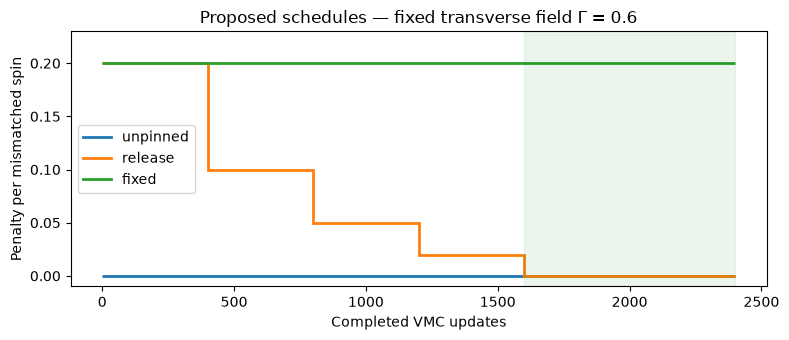

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for arm, stages in schedules.items():
    edges = [0]
    for updates, epsilon in stages:
        edges.append(edges[-1] + updates)
    ax.stairs([epsilon for updates, epsilon in stages], edges, label=arm,
              baseline=None, linewidth=2)
ax.axvspan(1600, 2400, color="green", alpha=0.08)
ax.set(xlabel="Completed VMC updates", ylabel="Penalty per mismatched spin",
       title="Proposed schedules — fixed transverse field Γ = 0.6", ylim=(-0.01, 0.23))
ax.legend()
fig.tight_layout()
plt.show()


## Frozen-guide diagnostics and target-Hamiltonian projection

Adaptive VMC traces describe optimization. Evaluate frozen checkpoints with
fresh RNG streams, independent of training and reference search.

At updates 1600, 2000 and 2400, for every branch, run fixed-parameter tempered
sampling from uniform, reference-aligned and inverse-reference starts. For
the baseline, use all three selected references for the latter two start
families. Use 128 chains/temperature, 400 warmup sweeps and 1024 measurement
sweeps, saving cold states every four sweeps. Record start families separately.
Extend this fixed budget only through an explicit protocol revision if mixing
remains unresolved. All diagnostic sweeps are outside the optimization budget.

Record target and training energy per site, local-energy variance (both total
and divided by $N$), reference overlaps for **all** bank references, interchain
agreement, acceptance rates, temperature round trips, autocorrelation estimates
with their reliability flags and unique configurations. Track the probability
mass across nearest-reference regions with deterministic tie-breaking; those
regions are descriptive and are not proven thermodynamic basins. Compare
starts and seeds. Good energy or round trips alone do not establish mixing.
The sampled local-energy variance estimates the quantum variance only when
the Born distribution is sampled correctly; its finite-chain estimate is not
a certified bound.

At final update 2400, freeze each guide and screen **every branch under $H_0$**:
four independent populations of 512 walkers, equilibration time 16, forward
time 16, eight cycles and two independent repeats, matching the existing L6
screen. Use fresh populations and measurement streams; save their starts.
No auxiliary term, adaptation or likelihood-feedback stage enters this screen.
Any optional projection with nonzero pinning is a separately labeled study.

Reconstruct pure diagonal statistics using the validated forward-walking
estimator. Pair independently generated replicas/populations to form
\[
q=\frac1N\sum_i s_i^{(a)}s_i^{(b)},\quad P(q),\quad \langle q^2\rangle,
\qquad C_{ij}=\langle Z_iZ_j\rangle-\langle Z_i\rangle\langle Z_j\rangle.
\]
Do not substitute the guide's Born samples or the mixed GFMC distribution for
the target ground-state distribution. Preserve per-cycle raw tags, descendant
counts, spins, weights, mixed/growth energies and estimator normalization.
Use the existing connected-spectrum definition and record its normalization.
The exact overlap grid is $q_k=-1+2k/N$ with $k=0,\ldots,N$; compare probability
masses on this shared grid without smoothing.

Screening alarms and repeat discrepancies retain the existing conventions:

| Diagnostic | Proposed screening threshold |
|---|---|
| Descendant genealogy | alarm if ESS < 8 or largest lineage > 0.5 in any island/cycle |
| Energy per site, repeat absolute difference | 0.001 |
| $\langle q^2\rangle$, repeat absolute difference | 0.01 |
| $P(q)$ total variation, $\frac12\sum_k|p_k-p'_k|$ | 0.05 |
| Connected-spectrum mode differences | $|c_k-c'_k|/\max(|c_k|,|c'_k|,0.001)\le0.10$ |

Apply observable comparisons also across references and seeds within each
disorder, reporting all discrepancies rather than only pass counts. These are
diagnostic thresholds, not confidence intervals. Two repeats cannot establish
systematic accuracy. Genealogical ESS is distinct from VMC autocorrelation ESS.

Evidence for a useful intervention would be lower **target** energy fluctuations
after release, better genealogy under $H_0$, and reproducible correlations and
$P(q)$ across references, seeds and repeats. Improvement only while pinned,
or stable energy with reference-dependent overlaps, does not meet that goal.
Even a successful screen requires population-size, projection-time, start and
training-saturation checks before a ground-state claim. Predefine any follow-up
escalation equally across compared arms; this draft does not schedule it.


## Provenance and implementation boundary

Save the design version, full configuration and source hashes; graph and bond
arrays; classical search trajectories and candidate bank; selected reference
bitstrings and selection decisions; initialization checkpoint; model, Adam,
sampler and RNG checkpoint states; every training stage and elapsed time;
frozen diagnostics; raw projection data; all failures, alarms and exclusions.
Use independent `SeedSequence` namespaces for search, initial sampling,
training, frozen diagnostics and projection; persist namespace definitions
and states so resumption reproduces the continuation. Preserve all completed
branches and stop failed branches with a recorded reason; no automatic retry
loop, reference substitution or schedule tuning based on favorable results.

Implementation should add an explicit auxiliary-field schedule path using
`sampled_simple_guides.local_energy`, `energy_loss`, `TemperedChains` and
`simple_guides.RBM`. The existing trainer's `steps` is per transverse-field
stage and its field schedule is implicit; it cannot represent this budget by
merely changing one argument. Use a separate source snapshot for a future run.

Before any scientific launch, validate the diagonal penalty, $\epsilon=0$
recovery and covariance gradient against exact small-system calculations on
AutoDL; verify resumed versus uninterrupted optimizer/sampler continuation;
audit the target measurement Hamiltonian. The checks executed below validate
only the design arithmetic and notebook, not a trainer implementation.

## Decisions to settle before implementation

1. Keep $\epsilon_0=0.20$ as the single pilot strength, or add a weaker 0.05
   schedule? A strength scan increases both training and measurement scope.
2. Keep three references and 2400 updates/branch, including 800 at zero
   pinning? This gives a bounded first test of reference dependence and release.
3. Keep the proposed 128-start classical search, 2.16 energy window and
   distance-11 diversity rule? Bank coverage must be reviewed before selection
   can be considered adequate.

**Current result: protocol draft only. Auxiliary-field usefulness, quantum-gap
changes and ground-state convergence are all unmeasured.**
